# Laboratorio Dry Bean — CRISP-DM + TDSP + Scrum ML

**Clasificación automática de variedades de frijol seco a partir de características geométricas**

| Campo | Detalle |
|---|---|
| Dataset | Dry Bean Dataset (UCI ML Repository, id 602) |
| Registros | 13 611 originales · 13 543 tras eliminar duplicados |
| Variables | 16 predictoras numéricas + `Class` (objetivo) |
| Clases | 7 variedades |
| Equipo | Marko David García · Alejandro Meneses · Henry Rosenstiehl |
| Curso | Gerencia de Proyectos — UAO |
| Entregable | 1 de 3 — notebook ejecutado |

## Cómo leer este notebook

El notebook sigue **exactamente** las seis fases de **CRISP-DM**. Cada fase tiene su carpeta con
la evidencia (README + artefactos) y los datos se organizan en **capas tipo medallón**:

```text
01_comprension_negocio/   problema, objetivos y criterios de éxito
02_comprension_datos/     perfil de calidad y distribución de clases
03_preparacion_datos/     manifiesto y decisiones de limpieza
04_modelado/              modelos .joblib (baseline y final)
05_evaluacion/            métricas, matrices y predicciones
06_despliegue/            demo de predicción
data/bronze/              datos originales sin modificar (CSV de UCI)
data/silver/              dataset limpio y tipado
data/gold/                train/test listos para modelar
src/taller1/              código reutilizable (carga, modelado, reportes)
```

> **Reproducibilidad:** todas las particiones y modelos usan `random_state=42`. El hash SHA-256
> del CSV original se guarda en `03_preparacion_datos/data_manifest.json`.

## 0. Preparación del entorno

Se importan las librerías y se ancla la raíz del proyecto para que las rutas funcionen sin
importar desde dónde se abra el notebook. El paquete `taller1` contiene la misma lógica en
código reutilizable: el notebook explica el *porqué*, `src/` garantiza el *cómo* repetible.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import cross_val_score

from taller1 import data, eda, features, modeling, reporting
from taller1.config import (
    FINAL_MODEL_FILE,
    PREDICTIONS_FILE,
    RANDOM_STATE,
    TARGET_COLUMN,
    ensure_directories,
)

ensure_directories()
plt.rcParams["figure.figsize"] = (8, 4.5)
print("Proyecto:", PROJECT_ROOT)
print("Semilla fija:", RANDOM_STATE)

Proyecto: C:\Users\marko\OneDrive\Documentos\Marko\UAO\Semestre 3\Gerencia de Proyectos\taller1
Semilla fija: 42


## 1. Comprensión del negocio (CRISP-DM · fase 1)

**Problema simulado.** Una empresa agrícola clasifica manualmente los granos de frijol que
recibe. El proceso es lento, subjetivo y difícil de auditar: dos operarios pueden etiquetar el
mismo grano de forma distinta.

**Objetivo del proyecto.** Construir un modelo que prediga la variedad de frijol (`Class`) a
partir de 16 mediciones geométricas obtenidas por visión por computador, para apoyar el control
de calidad y reducir el tiempo de clasificación manual.

| Elemento | Definición |
|---|---|
| Variable objetivo | `Class` (7 variedades) |
| Tipo de problema | Clasificación multiclase supervisada |
| Métrica principal | **F1 macro** (todas las clases pesan igual) |
| Métrica secundaria | Accuracy (proporción de aciertos globales) |
| Criterio de éxito | F1 macro ≥ 0.90 en el conjunto de prueba |
| Uso previsto | Apoyo a la decisión: el operario confirma o corrige la predicción |
| Riesgo principal | Confundir variedades con forma y tamaño similares |

**Tipo de problema:** clasificación, no regresión, porque la salida es una categoría discreta
(la variedad) y no un valor continuo.

## 2. Comprensión de los datos (CRISP-DM · fase 2)

Se cargan los datos **originales sin transformarlos** desde `data/bronze/dry_bean.csv`. Si el
archivo no existe, la función lo descarga del repositorio oficial de UCI y deja constancia del
hash para versionado (TDSP).

In [2]:
df = data.load_raw_dataset()
print("Fuente oficial:", data.DATASET_PAGE)
df.head()

Fuente oficial: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
print("Dimensiones (filas, columnas):", df.shape)
print("\nTipos de datos y valores no nulos:")
df.info()

Dimensiones (filas, columnas): (13611, 17)

Tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  flo

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.28,29324.10,20420.00,36328.00,44652.00,61332.00,254616.00
Perimeter,13611.0,855.28,214.29,524.74,703.52,794.94,977.21,1985.37
MajorAxisLength,13611.0,320.14,85.69,183.60,253.30,296.88,376.50,738.86
MinorAxisLength,13611.0,202.27,44.97,122.51,175.85,192.43,217.03,460.20
AspectRatio,13611.0,1.58,0.25,1.02,1.43,1.55,1.71,2.43
Eccentricity,13611.0,0.75,0.09,0.22,0.72,0.76,0.81,0.91
ConvexArea,13611.0,53768.20,29774.92,20684.00,36714.50,45178.00,62294.00,263261.00
EquivDiameter,13611.0,253.06,59.18,161.24,215.07,238.44,279.45,569.37
Extent,13611.0,0.75,0.05,0.56,0.72,0.76,0.79,0.87
Solidity,13611.0,0.99,0.00,0.92,0.99,0.99,0.99,0.99


### Actividad del estudiante (Paso 3)

1. **¿Cuántas columnas tiene el dataset?** 17: 16 variables predictoras numéricas y la columna
   objetivo `Class`.
2. **¿Cuál es la variable objetivo?** `Class`, que contiene la variedad de frijol.
3. **¿El problema es de clasificación o regresión?** De clasificación multiclase (7 etiquetas).

### Interpretación de `describe()`

- Las escalas son muy distintas: `Area` se mueve en decenas de miles y `Solidity` entre 0 y 1.
  Por eso el modelo lineal necesita **estandarización**; el bosque aleatorio no la requiere.
- No hay columnas no numéricas aparte de la clase.
- Los valores máximos de `Area`, `Perimeter` y `ConvexArea` están muy por encima de la media:
  son granos grandes (probablemente **BOMBAY**), no errores de captura. Se conservan porque son
  observaciones reales.

In [5]:
missing_values = df.isna().sum()
duplicated_rows = int(df.duplicated().sum())

print("Valores nulos por columna (máximo):", int(missing_values.max()))
print("Columnas con nulos:", int((missing_values > 0).sum()))
print("Filas duplicadas:", duplicated_rows)

Valores nulos por columna (máximo): 0
Columnas con nulos: 0
Filas duplicadas: 68


In [6]:
class_counts = data.class_distribution(df)
class_counts

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: registros, dtype: int64

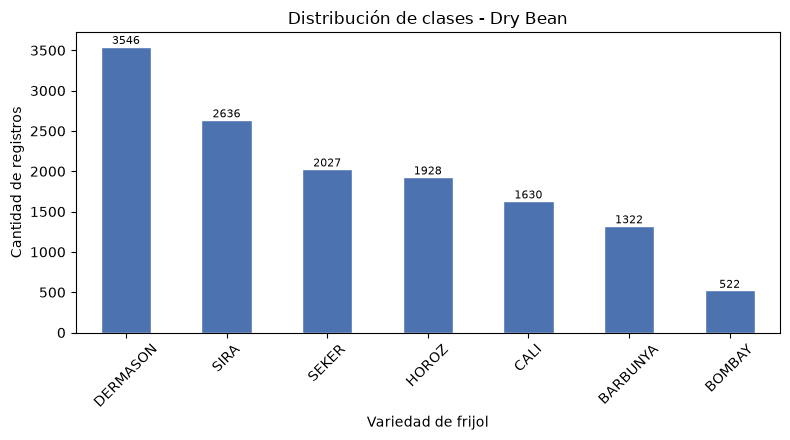

In [7]:
fig = reporting.plot_class_distribution(class_counts)
plt.show()

### Pregunta: ¿las clases están balanceadas?

Nota: al eliminar los 68 duplicados, `HOROZ` pasa de 1928 a **1860** registros. Es la única clase afectada, así que la limpieza reduce el desbalance sin cambiar el orden de las variedades.

**No.** La clase mayoritaria (`DERMASON`, 3546 registros) tiene casi **7 veces** más ejemplos
que la minoritaria (`BOMBAY`, 522). Efectos esperados:

- El modelo ve muchas más muestras de las clases frecuentes y tiende a predecirlas mejor.
- `accuracy` puede ser alta aunque una clase minoritaria se prediga mal, porque está dominada
  por las clases grandes. Por eso se reporta **F1 macro**, que promedia el F1 de cada clase
  con el mismo peso.
- Mitigaciones aplicadas: partición **estratificada** (mantiene proporciones en train/test) y
  `class_weight="balanced"` en el bosque aleatorio.

### 2.1 Perfil numérico y valores atípicos

Antes de modelar hay que responder tres preguntas: **¿cómo se distribuye cada variable?**,
**¿hay valores extremos?** y **¿los extremos son errores o granos reales?**.

El EDA se calcula sobre el dataset **sin duplicados** (13 543 registros). La limpieza formal se
documenta en la fase 3; aquí solo se evita contar dos veces la misma observación.

In [8]:
df_eda, _ = data.remove_duplicates(df)
feature_columns = [column for column in df_eda.columns if column != TARGET_COLUMN]

numeric_profile = eda.numeric_profile(df_eda, feature_columns)
numeric_profile

,media,desv_std,min,p25,mediana,p75,max,asimetria,curtosis,coef_variacion
variable,,,,,,,,,,
Area,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000,2.9471,10.7415,0.5541
Perimeter,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700,1.6280,3.5764,0.2511
MajorAxisLength,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602,1.3658,2.5437,0.2682
MinorAxisLength,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985,2.2320,6.6099,0.2226
AspectRatio,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303,0.5890,0.1548,0.1551
Eccentricity,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114,-1.0649,1.3958,0.1224
ConvexArea,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000,2.9361,10.6848,0.5551
EquivDiameter,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744,1.9473,5.1647,0.2344
Extent,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662,-0.8957,0.6523,0.0653


In [9]:
outliers = eda.outlier_report(df_eda, feature_columns)
outliers.head(8)

,variable,limite_inferior,limite_superior,n_atipicos,pct_atipicos
0,Eccentricity,0.57,0.95,833,6.15
1,Solidity,0.98,1.00,774,5.72
2,ShapeFactor4,0.99,1.00,760,5.61
3,MinorAxisLength,113.85,279.28,567,4.19
4,Area,-1366.75,99031.25,551,4.07
5,ConvexArea,-1857.50,100890.50,549,4.05
6,ShapeFactor1,0.00,0.01,533,3.94
7,EquivDiameter,117.99,376.50,526,3.88


**Lectura del perfil numérico**

- **Asimetría fuerte a la derecha** en las variables de tamaño: `Area` (2.95), `ConvexArea`
  (2.94) y `MinorAxisLength` (2.23). La cola la produce `BOMBAY`, que es mucho más grande que el
  resto. Esto justifica escalar para el modelo lineal y no tocar los datos para los árboles.
- **Variables casi constantes:** `Solidity` (CV = 0.005) y `ShapeFactor4` (CV = 0.004). Aportan
  poca variación, aunque el bosque aún las usa.
- **Valores atípicos por IQR:** `Eccentricity` (833, 6.2 %), `Solidity` (774, 5.7 %),
  `ShapeFactor4` (760, 5.6 %) y `Area` (551, 4.1 %). Son granos reales en los extremos de la
  distribución, no errores de captura: **se conservan**. Eliminarlos borraría justamente la señal
  que distingue a `BOMBAY`.

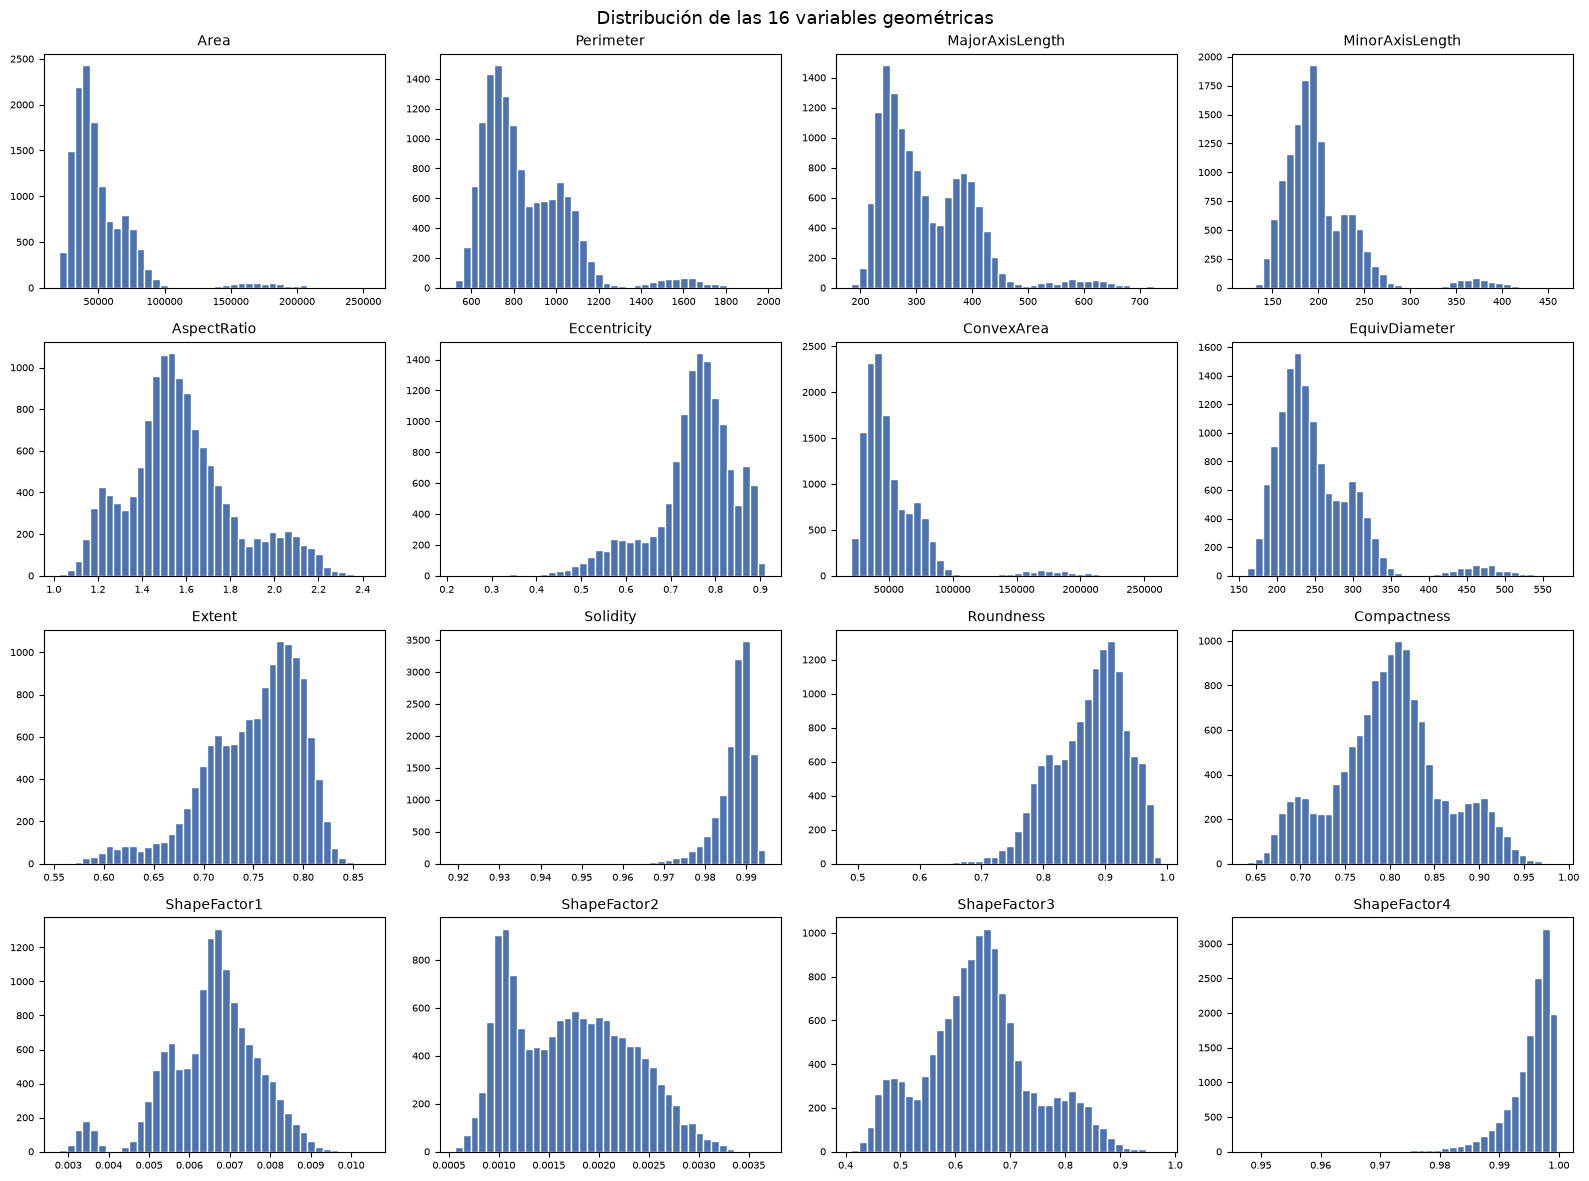

In [10]:
figure = eda.plot_feature_histograms(df_eda, feature_columns)
plt.show()

### 2.2 Relaciones entre variables

Con 16 variables geométricas es esperable que varias midan casi lo mismo. La matriz de
correlación permite detectarlo antes de interpretar coeficientes.

In [11]:
correlation = eda.correlation_matrix(df_eda, feature_columns)
top_pairs = eda.top_correlations(correlation, n=10)
top_pairs

,variable_1,variable_2,correlacion
0,Area,ConvexArea,0.999940
1,Compactness,ShapeFactor3,0.998684
2,Perimeter,EquivDiameter,0.991453
3,AspectRatio,Compactness,-0.987644
4,ConvexArea,EquivDiameter,0.985255
5,Area,EquivDiameter,0.984998
6,Eccentricity,ShapeFactor3,-0.981058
7,AspectRatio,ShapeFactor3,-0.978528
8,Perimeter,MajorAxisLength,0.977561
9,Eccentricity,Compactness,-0.970308


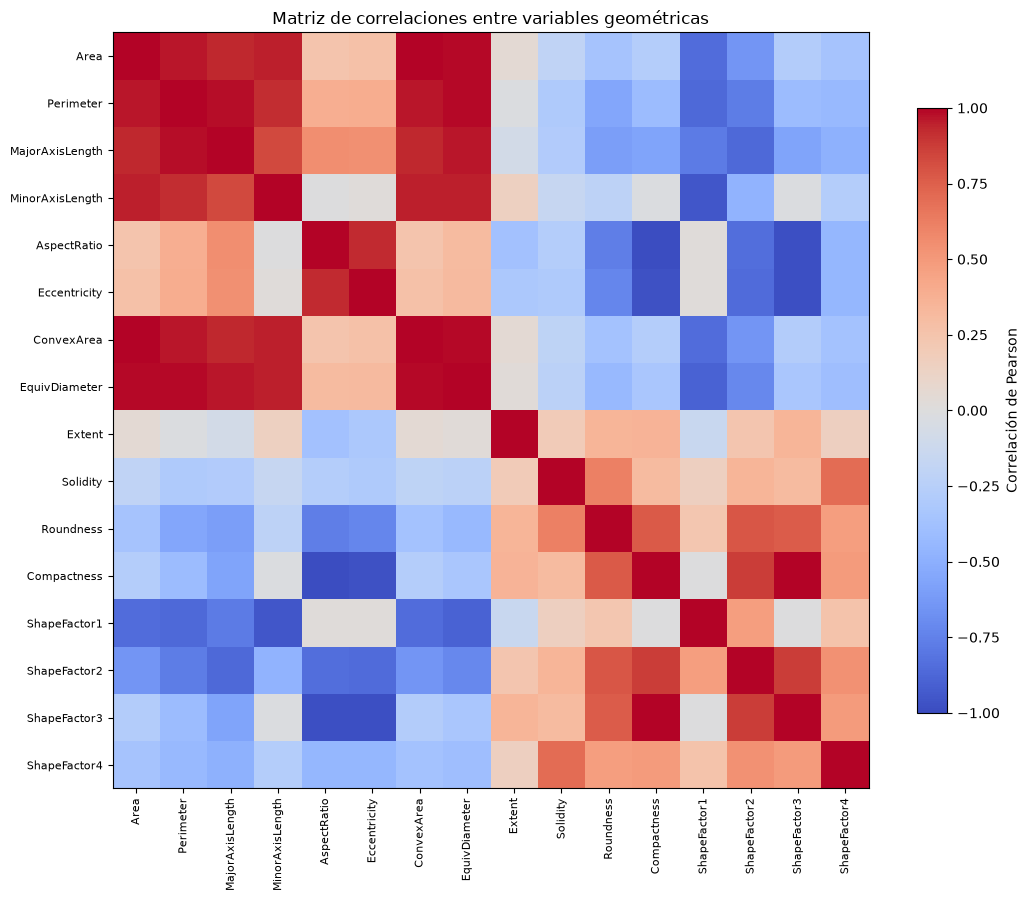

In [12]:
figure = eda.plot_correlation_heatmap(correlation)
plt.show()

**Hallazgo: multicolinealidad alta.**

| Par | Correlación | Interpretación |
|---|---:|---|
| `Area` – `ConvexArea` | 0.9999 | Prácticamente la misma variable |
| `Compactness` – `ShapeFactor3` | 0.9987 | Duplican información de forma |
| `Perimeter` – `EquivDiameter` | 0.9915 | Diámetro y perímetro crecen juntos |
| `AspectRatio` – `Compactness` | −0.9876 | Relación inversa casi perfecta |

Consecuencias para el modelado:

1. Las 16 variables contienen en la práctica **unas 10 dimensiones independientes**.
2. Los **coeficientes** de la regresión logística no deben interpretarse de forma causal: la
   multicolinealidad los reparte entre variables correlacionadas.
3. La **importancia de Random Forest** también se diluye entre variables redundantes; por eso se
   interpreta por bloques (tamaño, forma, contorno) y no por variable aislada.
4. No es necesario eliminar variables para predecir, pero sí para explicar.

### 2.3 Separabilidad por clase

El EDA más útil para este problema es preguntar: **¿qué variable separa mejor las variedades?**

- **Perfil por clase:** media de cada variable estandarizada (z-score). Valores positivos
  indican que la variedad está por encima del promedio; negativos, por debajo.
- **Eta cuadrado:** proporción de la varianza de una variable que explica la clase. Cercano a 1
  significa que la variable separa bien; cercano a 0, que apenas aporta.

In [13]:
class_profile = eda.class_profiles(df_eda, TARGET_COLUMN, feature_columns)
separation = eda.class_separation(df_eda, TARGET_COLUMN, feature_columns)

print("Variables con mayor poder discriminante:")
display(separation.head(8))
print("Variables con menor poder discriminante:")
display(separation.tail(3))

Variables con mayor poder discriminante:


,variable,eta_cuadrado
0,Area,0.9279
1,ConvexArea,0.9277
2,EquivDiameter,0.9187
3,Perimeter,0.9151
4,MinorAxisLength,0.9086
5,MajorAxisLength,0.9056
6,ShapeFactor2,0.8440
7,ShapeFactor1,0.8429


Variables con menor poder discriminante:


,variable,eta_cuadrado
13,ShapeFactor4,0.3589
14,Solidity,0.2192
15,Extent,0.1592


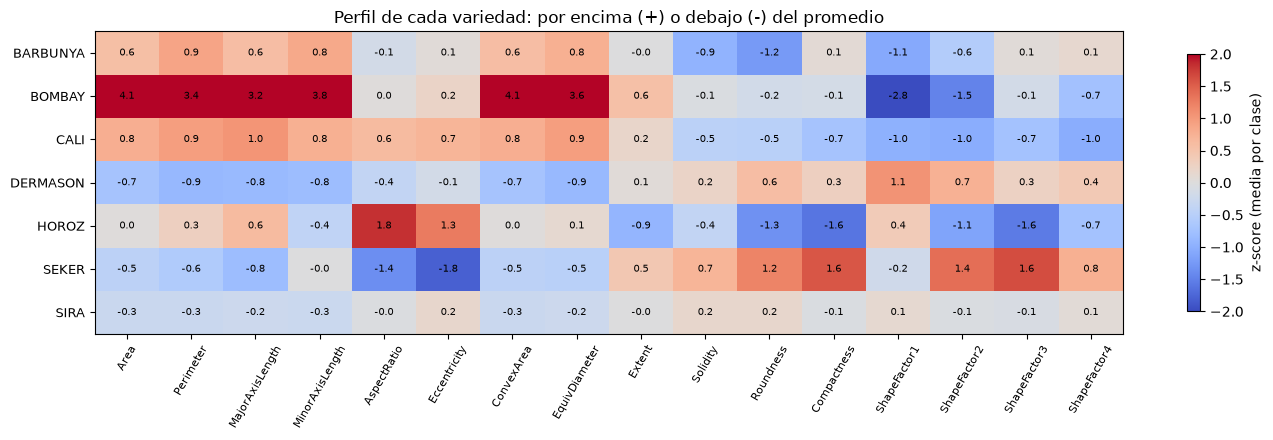

In [14]:
figure = eda.plot_class_profiles(class_profile)
plt.show()

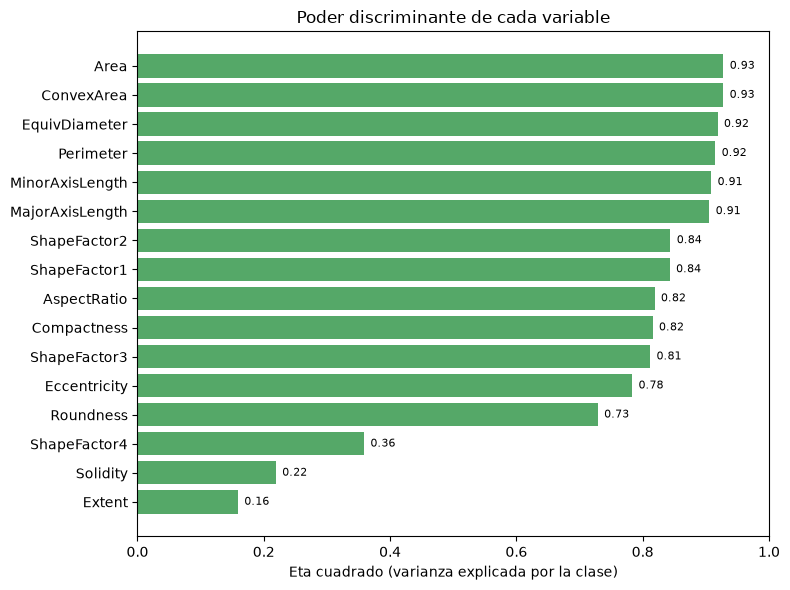

In [15]:
figure = eda.plot_separability(separation)
plt.show()

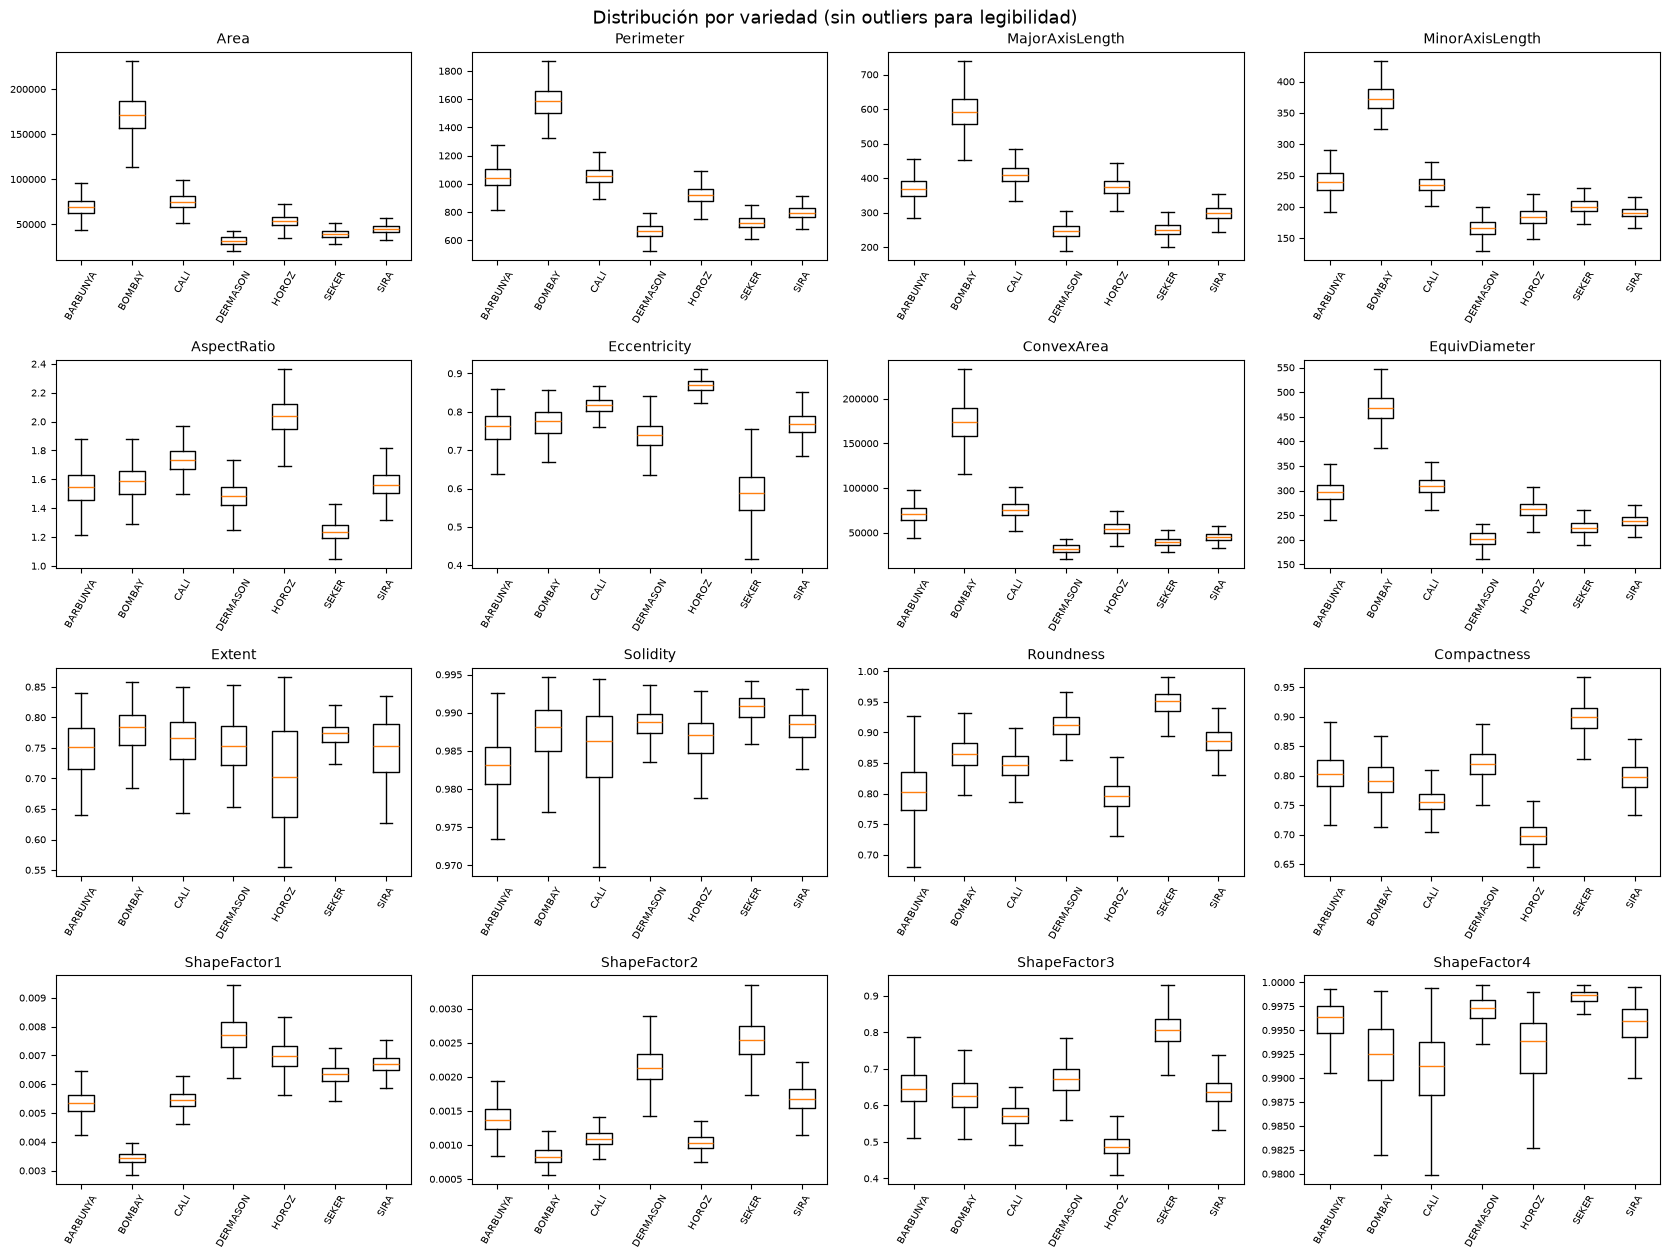

In [16]:
figure = eda.plot_boxplots_by_class(df_eda, TARGET_COLUMN, feature_columns)
plt.show()

**Lectura de la separabilidad**

- **Seis variables superan eta² = 0.90:** `Area` (0.93), `ConvexArea` (0.93),
  `EquivDiameter` (0.92), `Perimeter` (0.92), `MinorAxisLength` (0.91) y `MajorAxisLength`
  (0.91). Son medidas de **tamaño** y separan casi por sí solas.
- **Las más débiles** son `Extent` (0.16), `Solidity` (0.22) y `ShapeFactor4` (0.36): describen
  detalles del contorno que casi no cambian entre variedades.

**Perfil de cada variedad (z-score):**

| Variedad | Rasgo dominante | z-score |
|---|---|---:|
| `BOMBAY` | Mucho más grande que todas | Area +4.1, ConvexArea +4.1 |
| `HOROZ` | Alargada y excéntrica | AspectRatio +1.8, Eccentricity +1.3 |
| `SEKER` | Redonda y compacta | Roundness +1.2, Compactness +1.6 |
| `DERMASON` | Compacta tirando a pequeña | ShapeFactor1 +1.1, Area −0.7 |
| `BARBUNYA` | Contorno poco sólido | Solidity −0.9, ShapeFactor1 −1.1 |
| `SIRA` | **Perfil promedio** | todas sus variables entre −0.3 y +0.3 |

**El caso `SIRA` explica el modelo.** Es la única variedad sin un rasgo extremo: se parece al
promedio y por eso es la más difícil de separar. Eso anticipa su F1 de 0.87 y su confusión con
`DERMASON`, que también es de tamaño medio. El EDA permitió **predecir el error del modelo antes
de entrenarlo**.

### 2.4 Hallazgos del EDA y su efecto en el modelado

| Hallazgo | Decisión que justifica |
|---|---|
| Distribuciones asimétricas con colas largas | Estandarizar para el modelo lineal; no escalar para árboles |
| Outliers legítimos (BOMBAY) | No eliminarlos: son la señal de una clase |
| Multicolinealidad alta | No interpretar coeficientes aislados; agrupar importancia por bloques |
| 6 variables con eta² > 0.90 | El problema es casi linealmente separable → el baseline competirá con el bosque |
| `SIRA` con perfil promedio | Anticipa su F1 bajo y la confusión con `DERMASON` |
| Variables casi constantes (`Solidity`, `ShapeFactor4`) | Candidatas a eliminar en una versión futura, no en esta |

Estos hallazgos se usan en las fases 3, 4 y 5, y se resumen en
[`docs/reporte_crisp_dm.md`](../docs/reporte_crisp_dm.md). Las tablas y gráficas completas quedan
en `02_comprension_datos/`.

## 3. Preparación de los datos (CRISP-DM · fase 3)

**Decisiones y su justificación:**

| Decisión | Justificación |
|---|---|
| Eliminar 68 filas duplicadas | Un registro repetido sesga el entrenamiento y la evaluación. Las 68 pertenecen a `HOROZ`. |
| Conservar valores extremos | Son granos reales, no errores; recortarlos perdería información de BOMBAY. |
| No imputar nulos | El dataset no tiene valores faltantes (0 nulos). |
| Estratificar el split | Mantiene la proporción de las 7 clases en train y test. |
| `random_state=42` | Reproducibilidad exigida por TDSP. |
| Guardar el dataset limpio | Trazabilidad: `data/silver/dry_bean_clean.csv` y splits en `data/gold/`. |

In [17]:
clean, removed = data.remove_duplicates(df)
print(f"Duplicados eliminados: {removed}")
print(f"Registros antes: {len(df)} | después: {len(clean)}")

quality = data.data_quality_summary(clean)
quality

Duplicados eliminados: 68
Registros antes: 13611 | después: 13543


{'n_registros': 13543,
 'n_columnas': 17,
 'n_features': 16,
 'valores_nulos': 0,
 'columnas_con_nulos': 0,
 'filas_duplicadas': 0,
 'columnas_no_numericas': ['Class'],
 'clases': ['BARBUNYA',
  'BOMBAY',
  'CALI',
  'DERMASON',
  'HOROZ',
  'SEKER',
  'SIRA']}

In [18]:
data.save_processed(clean)
manifest = data.build_manifest(clean)
data.save_manifest(manifest)
print("Dataset limpio guardado en: data/silver/dry_bean_clean.csv")
print("SHA-256 del CSV original:", manifest["sha256"])

Dataset limpio guardado en: data/silver/dry_bean_clean.csv
SHA-256 del CSV original: c91a086bb4357e69409d23287ec22be1be9512145cead1d8ca988c918be38fcb


In [19]:
X = clean.drop(columns=TARGET_COLUMN)
y = clean[TARGET_COLUMN]

print("X:", X.shape, "| y:", y.shape)
print("Distribución de y:")
print(y.value_counts())

X: (13543, 16) | y: (13543,)
Distribución de y:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


In [20]:
X_train, X_test, y_train, y_test = features.split_train_test(X, y)

print(f"Entrenamiento: {X_train.shape[0]} registros")
print(f"Prueba:        {X_test.shape[0]} registros")
print("\nProporción de clases en test:")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(1))

Entrenamiento: 10834 registros
Prueba:        2709 registros

Proporción de clases en test:


Class
BARBUNYA     9.8
BOMBAY       3.8
CALI        12.0
DERMASON    26.2
HOROZ       13.7
SEKER       15.0
SIRA        19.5
Name: proportion, dtype: float64


La proporción de cada clase en prueba coincide con la del dataset completo: la estratificación
funcionó. **8 de cada 10** registros se usan para aprender y **2 de cada 10** quedan reservados
para medir el desempeño sobre datos nunca vistos.

## 4. Modelado (CRISP-DM · fase 4)

### 4.1 Modelo baseline: regresión logística

Un **baseline** es el modelo más simple razonable. Sirve como vara de medir: si un modelo
complejo no lo supera, no se justifica su costo. La regresión logística es interpretable,
rápida y adecuada para fronteras de decisión aproximadamente lineales.

Se encapsula en un `Pipeline` con `StandardScaler` para que el escalamiento se ajuste **solo con
datos de entrenamiento** y se aplique después a prueba; así se evita fuga de información.

In [21]:
baseline_model = modeling.build_baseline_model()
baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`

In [22]:
baseline_model.fit(X_train, y_train)
print("Modelo baseline entrenado:", type(baseline_model.named_steps["classifier"]).__name__)

Modelo baseline entrenado: LogisticRegression


In [23]:
y_pred_baseline = baseline_model.predict(X_test)

accuracy_baseline = accuracy_score(y_test, y_pred_baseline)
f1_baseline = f1_score(y_test, y_pred_baseline, average="macro")

print(f"Accuracy baseline: {accuracy_baseline:.4f}")
print(f"F1 macro baseline: {f1_baseline:.4f}")
print(classification_report(y_test, y_pred_baseline, zero_division=0))

Accuracy baseline: 0.9195
F1 macro baseline: 0.9306
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



### Pregunta: ¿por qué F1 macro es más informativo que accuracy?

Porque `accuracy` suma todos los aciertos por igual, de modo que acertar en `DERMASON` (709
casos en prueba) pesa mucho más que acertar en `BOMBAY` (104). Un modelo que ignorara la clase
minoritaria aún podría mostrar una accuracy alta. **F1 macro** calcula el F1 de cada clase y
luego promedia sin importar cuántos ejemplos tenga: castiga con dureza que una variedad se
prediga mal, que es justo lo que importa en control de calidad.

### 4.2 Modelo alternativo: Random Forest

El bosque aleatorio combina 200 árboles entrenados sobre muestras y subconjuntos de variables
distintos. Captura relaciones no lineales e interacciones entre medidas de forma y tamaño.
`class_weight="balanced"` compensa la diferencia de frecuencia entre variedades.

No requiere escalamiento porque cada división de un árbol compara una variable contra un
umbral; la escala no altera el orden de los valores. Se compara con el baseline para justificar
(o descartar) su uso.

In [24]:
forest_model = modeling.build_random_forest(n_estimators=200)
forest_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [25]:
forest_model.fit(X_train, y_train)
print("Random Forest entrenado con", forest_model.n_estimators, "árboles")

Random Forest entrenado con 200 árboles


In [26]:
y_pred_forest = forest_model.predict(X_test)

accuracy_forest = accuracy_score(y_test, y_pred_forest)
f1_forest = f1_score(y_test, y_pred_forest, average="macro")

print(f"Accuracy Random Forest: {accuracy_forest:.4f}")
print(f"F1 macro Random Forest: {f1_forest:.4f}")
print(classification_report(y_test, y_pred_forest, zero_division=0))

Accuracy Random Forest: 0.9195
F1 macro Random Forest: 0.9310
              precision    recall  f1-score   support

    BARBUNYA       0.92      0.90      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.95      0.96       372
       SEKER       0.92      0.96      0.94       406
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



## 5. Evaluación (CRISP-DM · fase 5)

### 5.1 Comparación de modelos

In [27]:
results = pd.DataFrame(
    {
        "modelo": ["Logistic Regression", "Random Forest"],
        "accuracy": [accuracy_baseline, accuracy_forest],
        "f1_macro": [f1_baseline, f1_forest],
    }
).round(4)

results

,modelo,accuracy,f1_macro
0,Logistic Regression,0.9195,0.9306
1,Random Forest,0.9195,0.9310


In [28]:
comparison = modeling.compare_models(
    [
        modeling.evaluate_model(baseline_model, X_test, y_test, "Logistic Regression"),
        modeling.evaluate_model(forest_model, X_test, y_test, "Random Forest"),
    ]
)
comparison

,modelo,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
0,Random Forest,0.9195,0.9310,0.9195,0.9312,0.9310
1,Logistic Regression,0.9195,0.9306,0.9197,0.9311,0.9303


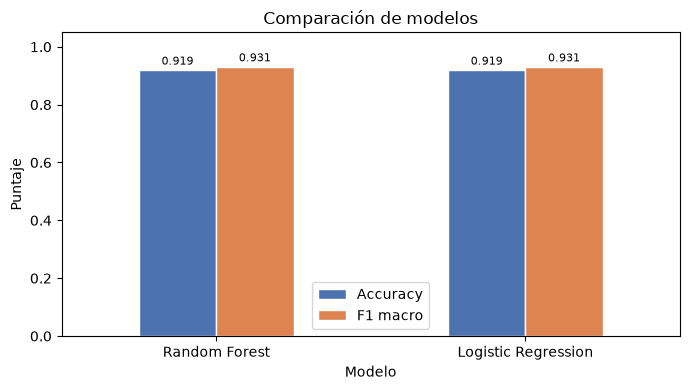

In [29]:
fig = reporting.plot_model_comparison(comparison)
plt.show()

### Decisión CRISP-DM

Los dos modelos quedan prácticamente empatados: **accuracy 0.9195** en ambos y **F1 macro
0.9310 vs 0.9306**. La diferencia a favor del bosque aleatorio es de 0.0004, es decir, menos de
una décima de punto porcentual.

Criterio aplicado: **priorizar F1 macro**, revisar errores por clase y, si el desempeño es muy
parecido, preferir el modelo más simple. Con ese criterio estricto, la regresión logística
sería defendible (es más simple e interpretable). Sin embargo, se selecciona **Random Forest**
como modelo final por tres razones:

1. Su F1 macro es ligeramente superior y no depende de supuestos de linealidad.
2. Ofrece importancia de variables, útil para explicar el resultado a la empresa.
3. Con nuevas imágenes, las relaciones entre medidas pueden ser no lineales; el bosque es más
   robusto a ese cambio.

El empate técnico es en sí un hallazgo: **las 16 medidas geométricas separan las variedades casi
linealmente**, por lo que la complejidad adicional aporta poco. En un proyecto real esto se
documentaría y se revisaría con el Product Owner antes de asumir el costo de mantener un modelo
más pesado.

### 5.2 Matriz de confusión del modelo final

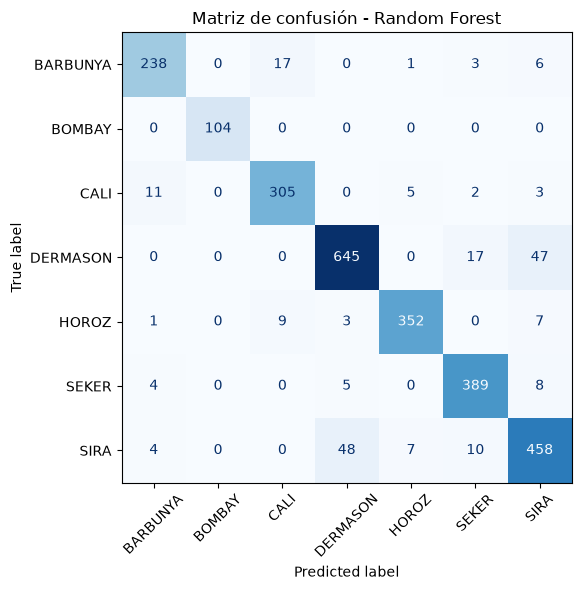

In [30]:
result_forest = modeling.evaluate_model(forest_model, X_test, y_test, "Random Forest")
fig = reporting.plot_confusion_matrix(result_forest)
plt.show()

### Pregunta: ¿qué clases se confunden más entre sí?

| Confusión | Casos | Explicación basada en variables |
|---|---:|---|
| SIRA → DERMASON | 48 | Ambas son alargadas y de tamaño medio; comparten proporciones de eje y compacidad. |
| DERMASON → SIRA | 47 | Es la misma frontera vista al revés: el modelo duda entre las dos. |
| DERMASON → SEKER | 17 | SEKER es redondeada y algo menor, pero los granos límite se solapan. |
| BARBUNYA → CALI | 17 | Tamaño y área parecidos; cambia sobre todo la forma del contorno. |
| CALI → BARBUNYA | 11 | Misma frontera: variedades visualmente próximas. |

`BOMBAY` se clasifica perfectamente (F1 = 1.00) porque es mucho más grande que el resto:
`Area` y `Perimeter` la separan sin ambigüedad. `SIRA` es la clase con peor F1 (0.87), coherente
con ser la que más se confunde con `DERMASON`. En total hay **218 errores de 2709** predicciones
(8.1 %).

**Implicación de negocio:** las confusiones ocurren entre variedades de forma y tamaño
similares. Para reducirlas haría falta una señal que las medidas geométricas no capturan, por
ejemplo color o textura de la semilla.

### 5.3 Importancia de variables

In [31]:
feature_importance = modeling.feature_importance(forest_model, list(X.columns))
feature_importance.head(10).round(4)

,feature,importance
0,Perimeter,0.1092
1,ShapeFactor1,0.1021
2,Compactness,0.0952
3,ShapeFactor3,0.0939
4,MinorAxisLength,0.0929
5,EquivDiameter,0.0667
6,Roundness,0.0618
7,AspectRatio,0.0600
8,Eccentricity,0.0593
9,Area,0.0578


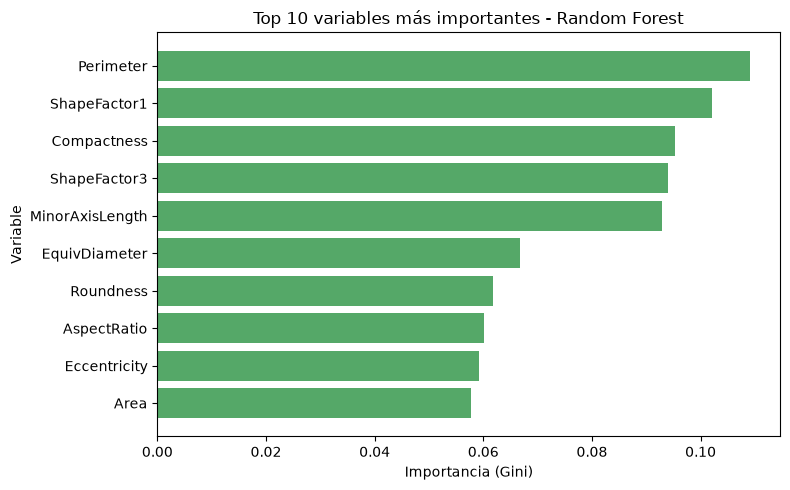

In [32]:
fig = reporting.plot_feature_importance(feature_importance, top_n=10)
plt.show()

`Perimeter`, `ShapeFactor1`, `Compactness`, `ShapeFactor3` y `MinorAxisLength` concentran la
mayor parte de la capacidad discriminante. Tiene sentido: describen el contorno y las
proporciones del grano, que es exactamente lo que distingue una variedad de otra.

**Advertencia:** la importancia indica qué variables usó el modelo para separar clases; **no
prueba causalidad** ni que esa variable sea la causa de la variedad.

### 5.4 Validación cruzada (extensión opcional A)

Una sola partición puede dar una estimación afortunada. La validación cruzada repite el
entrenamiento en 3 particiones distintas y reporta la dispersión del F1 macro: si la desviación
es pequeña, el resultado es estable.

In [33]:
cv_scores = cross_val_score(
    modeling.build_random_forest(n_estimators=100),
    X_train,
    y_train,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
)

print("F1 macro por partición:", [round(score, 4) for score in cv_scores])
print(f"Media: {cv_scores.mean():.4f} | Desviación estándar: {cv_scores.std():.4f}")

F1 macro por partición: [np.float64(0.9331), np.float64(0.9326), np.float64(0.9316)]
Media: 0.9324 | Desviación estándar: 0.0006


La media de la validación cruzada es coherente con el resultado en prueba y la desviación es
baja: el desempeño **no depende de una partición afortunada**. Esa estabilidad es el argumento
técnico para pasar a despliegue.

## 6. Despliegue (CRISP-DM · fase 6)

El despliegue de este laboratorio es una **demo local reproducible**: el modelo se serializa, se
vuelve a cargar desde disco y se usa para predecir. Guardar el artefacto permite que otra
persona lo use sin reentrenar y sin depender del notebook.

In [34]:
saved_path = modeling.save_model(forest_model, FINAL_MODEL_FILE)
print("Modelo guardado en:", saved_path.relative_to(PROJECT_ROOT))
print("Tamaño:", f"{saved_path.stat().st_size / 1024:.1f} KB")

Modelo guardado en: 04_modelado\random_forest_drybean.joblib
Tamaño: 25088.6 KB


In [35]:
loaded_model = modeling.load_model(FINAL_MODEL_FILE)

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)

print("Predicción:", prediction[0])
print("Valor real:", y_test.iloc[0])

Predicción: SEKER
Valor real: SEKER


In [36]:
def predict_bean_class(model, input_data):
    """Devuelve la variedad predicha para una fila con las 16 variables."""
    prediction = model.predict(input_data)
    return prediction[0]


example_prediction = predict_bean_class(loaded_model, sample)
print("Variedad predicha:", example_prediction)

Variedad predicha: SEKER


In [37]:
predictions_df = X_test.copy()
predictions_df["real_class"] = y_test.to_numpy()
predictions_df["predicted_class"] = y_pred_forest
predictions_df.to_csv(PREDICTIONS_FILE, index=False)

print("Predicciones exportadas en:", PREDICTIONS_FILE.relative_to(PROJECT_ROOT))
predictions_df[["real_class", "predicted_class"]].head()

Predicciones exportadas en: 05_evaluacion\predicciones_drybean.csv


,real_class,predicted_class
1223,SEKER,SEKER
11769,DERMASON,DERMASON
12059,DERMASON,DERMASON
7126,HOROZ,HOROZ
638,SEKER,SEKER


`taller1 predict --input nuevo_lote.csv` reutiliza el mismo artefacto para clasificar un lote
completo desde la línea de comandos. Esa es la forma en que el modelo llegaría al área de
calidad: un CSV con las mediciones entra, un CSV con la variedad predicha sale.

## 7. Conclusiones

1. **El objetivo se cumplió.** El modelo final alcanza **F1 macro 0.931** y **accuracy 0.9195**
   en datos no vistos, por encima del criterio de éxito planteado (≥ 0.90).
2. **Las 16 medidas geométricas son suficientes para separar casi linealmente las variedades.**
   La regresión logística queda a 0.0004 de F1 macro del bosque aleatorio; la complejidad extra
   aporta poco, aunque se conserva el bosque por su robustez y su capacidad de explicar la
   importancia de variables.
3. **El desbalance de clases se gestionó, no se ignoró.** La estratificación y el
   `class_weight` evitan que `BOMBAY` (la clase minoritaria) quede invisible, y el F1 macro
   hace visible el costo por clase.
4. **Los errores se concentran donde el negocio lo esperaría:** SIRA ↔ DERMASON y
   BARBUNYA ↔ CALI, variedades similares en forma y tamaño. `BOMBAY`, la más grande, se separa
   perfectamente.
5. **La reproducibilidad quedó garantizada:** semilla fija, hash del dataset, código en `src/`,
   pruebas automatizadas y artefactos versionables en las carpetas de cada fase.

### Qué haría falta antes de producción

- Validar con imágenes de lotes reales de la empresa, no solo del dataset académico.
- Definir el costo de cada error (no es lo mismo confundir dos variedades comerciales que una
  no comestible) y ajustar el umbral de decisión.
- Monitorear deriva de datos: cámara, iluminación o calibración distinta cambian las medidas.
- Versionar el modelo y exponerlo como servicio, con registro de predicciones para auditoría.
- Explorar variables adicionales (color, textura) para reducir las confusiones SIRA/DERMASON.

## 8. Trazabilidad del trabajo (TDSP + Scrum ML)

| Evidencia | Ubicación |
|---|---|
| Dataset original + hash SHA-256 | `data/bronze/dry_bean.csv`, `03_preparacion_datos/data_manifest.json` |
| Dataset limpio | `data/silver/dry_bean_clean.csv` |
| Splits listos para modelar | `data/gold/train.csv`, `data/gold/test.csv` |
| Perfil de calidad | `02_comprension_datos/perfil_datos.json` |
| Distribución de clases | `02_comprension_datos/distribucion_clases.png` |
| Métricas comparadas | `05_evaluacion/metricas_modelos.csv` |
| Reportes por clase | `05_evaluacion/classification_report_*.txt` |
| Matrices y gráficas | `05_evaluacion/*.png` |
| Predicciones | `05_evaluacion/predicciones_drybean.csv` |
| Resumen de la corrida | `05_evaluacion/resumen_ejecucion.json` |
| Modelo final | `04_modelado/random_forest_drybean.joblib` |
| Demo de predicción | `06_despliegue/ejemplo_prediccion.json` |
| Evidencia Scrum ML | `docs/scrum_ml.md` |
| Reporte CRISP-DM | `docs/reporte_crisp_dm.md` |

**Definition of Done del notebook:** se ejecuta de inicio a fin sin errores, carga el dataset,
reporta nulos y duplicados, entrena baseline y modelo alternativo, compara con accuracy y F1
macro, incluye matriz de confusión, guarda el modelo y explica los resultados en lenguaje
comprensible. ✅